# 12 · Zooms regionales para la presentación de la ET7

Mapas regionales de alta resolución a partir del caché de `itchi.cases` (mismos datos que el notebook 11).
Los mapas municipales dibujan cada municipio como polígono (no pintado sobre la malla), así que el PDF es
vectorial y el PNG sale a 300 dpi. Salida: `outputs/figures/casos/zooms/`.

| Zoom | Contenido | Diapositiva |
|---|---|---|
| 1 | Earl 2016, Sierra Norte de Puebla: clase municipal, declaratorias, Huauchinango | sesgo de declaratorias / anticipación |
| 2 | Emily 2005: municipios con declaratoria en clases 2 y 3 (recuadro automático) | clases desordenadas |
| 3 | Patricia 2015, 24 oct 12 UTC: lluvia de otro sistema en Texas y Coahuila | otros sistemas |
| 4 | Odile 2014: clase máxima por celda en Guerrero y Oaxaca | otros sistemas |
| 5 | Ubicación de los deslizamientos de Atoyac (Manuel) y Huauchinango (Earl) | anticipación (opcional) |

Para quitar los títulos y ponerlos en Canva: `TITULOS = False`.

In [1]:
# 1. Configuración
from pathlib import Path

import cartopy.crs as ccrs
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle

from itchi.cases import (CASES, DESLIZAMIENTOS, CaseConfig, declaratoria_inicio, load_declaratorias,
                         load_or_compute, municipal_event)
from itchi.constants import ITCHI_VERSION
from itchi.municipal import find_municipio
from itchi.plotting import (MapStyle, SIAT_DANGER_COLORS, classify_itchi_to_siat_levels, configure_map_axis,
                            get_crameri_colormap, plot_itchi_siat_levels)

PC = ccrs.PlateCarree()
cfg = CaseConfig()
EXP = "itchi"                                   # experimento por defecto (configs/default.yaml)
FIG_DIR = Path(cfg.fig_dir) / "zooms"; FIG_DIR.mkdir(parents=True, exist_ok=True)
FORMATOS = ("png", "pdf")                       # png 300 dpi para Canva; pdf vectorial
TITULOS = True                                  # False: sin título (se pone en Canva)
ETIQUETAS = ("0 Sin peligro", "1 Muy bajo", "2 Bajo", "3 Moderado", "4 Alto", "5 Extremo")
plt.rcParams.update({"font.size": 10, "axes.titlesize": 11, "savefig.dpi": 300})
print("itchi-core", ITCHI_VERSION, "| zooms en", FIG_DIR)

itchi-core 0.3.0 | zooms en /mnt/c/Users/adolf/Documents/ITCHI/itchi-core/outputs/figures/casos/zooms


In [2]:
# 2. Utilidades
def guardar(fig, nombre):
    for ext in FORMATOS:
        fig.savefig(FIG_DIR / f"{nombre}.{ext}", bbox_inches="tight")
    print("guardada", FIG_DIR / nombre)


def estilo_zoom(lo, la, paso=1.0, label_size=9.0):
    # recuadro en múltiplos de paso para que las marcas no lo agranden
    lo = (np.floor(lo[0] / paso) * paso, np.ceil(lo[1] / paso) * paso)
    la = (np.floor(la[0] / paso) * paso, np.ceil(la[1] / paso) * paso)
    return MapStyle(lon_extent=lo, lat_extent=la, lon_tick_spacing=paso, lat_tick_spacing=paso,
                    grid_spacing=paso, label_size=label_size, coastline_linewidth=0.9, border_linewidth=0.8)


def leyenda_clases(ax, clases=range(1, 6), extra=(), loc="lower left"):
    h = [Patch(facecolor=SIAT_DANGER_COLORS[k], edgecolor="0.4", lw=0.4, label=ETIQUETAS[k]) for k in clases]
    ax.legend(handles=h + list(extra), loc=loc, fontsize=8, frameon=True, framealpha=0.9)


def clase_municipal(Cc):
    # clase SIAT del máximo del evento en cada municipio (índice: CVEGEO)
    m = municipal_event(Cc).sel(exp=EXP).max("time")
    cls = np.asarray(classify_itchi_to_siat_levels(m.values), float)
    return pd.Series(cls, index=pd.Index(m["mun"].values.astype(str), name="CVEGEO"))


def municipios(Cc):
    g = Cc["gdf"]
    if g.crs is not None and g.crs.to_epsg() != 4326:
        g = g.to_crs(4326)
    g = g.assign(CVEGEO=g["CVEGEO"].astype(str))
    return g.assign(clase=g["CVEGEO"].map(clase_municipal(Cc)))


def mapa_municipal(ax, Cc, decl, st):
    # polígonos municipales coloreados por clase, límites estatales y municipios con declaratoria
    configure_map_axis(ax, crs=PC, style=st)
    g = municipios(Cc)
    sin = g[~(g["clase"] > 0)]
    ax.add_geometries(sin.geometry, crs=PC, facecolor="none", edgecolor="0.75", linewidth=0.2, zorder=2)
    for k in range(1, 6):
        sub = g[g["clase"] == k]
        if len(sub):
            ax.add_geometries(sub.geometry, crs=PC, facecolor=SIAT_DANGER_COLORS[k], edgecolor="0.45",
                              linewidth=0.2, zorder=3)
    est = g[["CVEGEO", "geometry"]].assign(ent=g["CVEGEO"].str[:2]).dissolve("ent")
    ax.add_geometries(est.geometry, crs=PC, facecolor="none", edgecolor="0.2", linewidth=0.8, zorder=4)
    con = g[g["CVEGEO"].isin(decl)]
    ax.add_geometries(con.geometry, crs=PC, facecolor="none", edgecolor="k", linewidth=1.4, zorder=5)
    return g


def trayectoria(ax, track, color="k"):
    ax.plot(track["lon"], track["lat"], "-", color=color, lw=1.0, transform=PC, zorder=6)
    ax.plot(track["lon"], track["lat"], "o", ms=2.5, color=color, transform=PC, zorder=6)


def regiones(ax, lon, lat, m_dir, m_ind):
    # región directa (continuo) y toda la región de atribución (discontinuo)
    for m, ls in ((np.asarray(m_dir, float), "-"), (np.asarray(m_dir | m_ind, float), "--")):
        if m.any():
            ax.contour(lon, lat, m, levels=[0.5], colors="k", linewidths=1.0, linestyles=ls, transform=PC, zorder=6)


def punto(ax, g, cvegeo, texto, dx=0.15, dy=0.15):
    c = g.loc[g["CVEGEO"] == str(cvegeo)].geometry.representative_point().iloc[0]
    ax.plot(c.x, c.y, "*", ms=15, mfc="white", mec="k", mew=1.2, transform=PC, zorder=8)
    ax.text(c.x + dx, c.y + dy, texto, fontsize=9, weight="bold", transform=PC, zorder=8,
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.85))
    return c


LEY_DECL = Line2D([], [], color="k", lw=1.4, label="Municipio con declaratoria")
LEY_TRAY = Line2D([], [], color="k", lw=1.0, marker="o", ms=3, label="Trayectoria (IBTrACS)")

In [3]:
# 3. Casos (solo lee el caché de scripts/casos.py)
CASOS_Z = ["EARL2016", "EMILY2005", "PATRICIA2015", "ODILE2014", "MANUEL2013"]
C = {c: load_or_compute(c, cfg) for c in CASOS_Z}
decl = load_declaratorias(cfg)
DECL = {c: set(map(str, declaratoria_inicio(decl, CASES[c]["atcf"]).index)) for c in CASOS_Z}
lon0 = C["EARL2016"]["ds"]["lon"].values
print("lon de la malla:", float(lon0.min()), "a", float(lon0.max()), "| CRS municipios:", C["EARL2016"]["gdf"].crs)
print("municipios con declaratoria:", {c: len(DECL[c]) for c in CASOS_Z})

EARL2016: leyendo earl2016.nc (17 posiciones)
EMILY2005: leyendo emily2005.nc (20 posiciones)
PATRICIA2015: leyendo patricia2015.nc (18 posiciones)
ODILE2014: leyendo odile2014.nc (35 posiciones)
MANUEL2013: leyendo manuel2013.nc (26 posiciones)
lon de la malla: -118.94999694824219 a -85.04999542236328 | CRS municipios: EPSG:4326
municipios con declaratoria: {'EARL2016': 2, 'EMILY2005': 191, 'PATRICIA2015': 102, 'ODILE2014': 6, 'MANUEL2013': 220}


## Zoom 1 · Earl (2016), Sierra Norte de Puebla

municipios en el recuadro por clase: {0.0: 122, 1.0: 219, 2.0: 21, 3.0: 16, 4.0: 12, 5.0: 446} | con declaratoria en el recuadro: 0 | declaratorias del caso: ['03002', '03008']
guardada /mnt/c/Users/adolf/Documents/ITCHI/itchi-core/outputs/figures/casos/zooms/zoom01_earl_sierra_norte


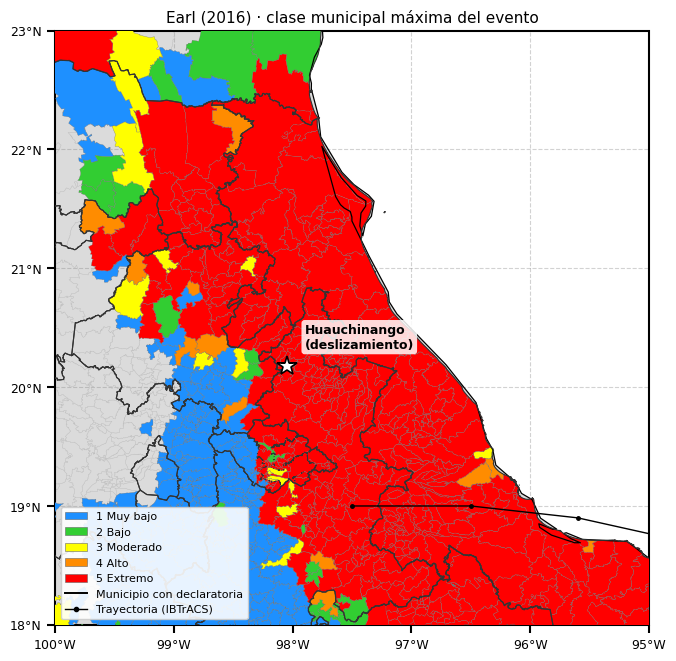

In [4]:
CASO = "EARL2016"
LON, LAT = (-100.0, -95.0), (18.0, 22.5)        # ajustar si hace falta más contexto
Cc, d = C[CASO], DESLIZAMIENTOS[CASO]
fig, ax = plt.subplots(figsize=(7.5, 6.5), subplot_kw={"projection": PC}, layout="constrained")
g = mapa_municipal(ax, Cc, DECL[CASO], estilo_zoom(LON, LAT, 1.0))
trayectoria(ax, Cc["track"])
cv = find_municipio(Cc["gdf"], d["municipio"], d["cve_ent"], d.get("cvegeo"))
punto(ax, g, cv, f"{d['municipio']}\n(deslizamiento)")
dentro = g.cx[LON[0]:LON[1], LAT[0]:LAT[1]]
print("municipios en el recuadro por clase:", dentro["clase"].value_counts().sort_index().to_dict(),
      "| con declaratoria en el recuadro:", int(dentro["CVEGEO"].isin(DECL[CASO]).sum()),
      "| declaratorias del caso:", sorted(DECL[CASO]))
leyenda_clases(ax, extra=[LEY_DECL, LEY_TRAY])
if TITULOS:
    ax.set_title("Earl (2016) · clase municipal máxima del evento")
guardar(fig, "zoom01_earl_sierra_norte")

## Zoom 2 · Emily (2005), declaratorias en clases 2 y 3
El recuadro se calcula con los municipios en clase 2 o 3 que tienen declaratoria. Si quedan dos grupos lejanos, fija `LON` y `LAT` a mano.

clase 2–3 con declaratoria: 49 | por estado (CVE_ENT): {'31': 48, '23': 1}
recuadro automático: [-93.3 -86.2] [16.9 22.3]
guardada /mnt/c/Users/adolf/Documents/ITCHI/itchi-core/outputs/figures/casos/zooms/zoom02_emily_clases_2_3


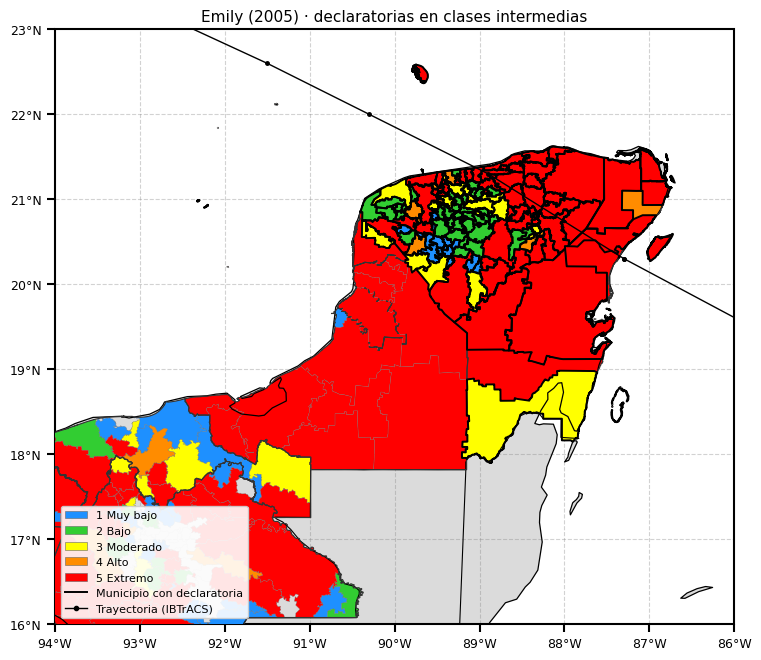

In [5]:
CASO = "EMILY2005"
Cc = C[CASO]
g0 = municipios(Cc)
foco = g0[g0["clase"].isin([2, 3]) & g0["CVEGEO"].isin(DECL[CASO])]
if foco.empty:                                   # respaldo: cualquier clase ≥ 2 con declaratoria
    foco = g0[(g0["clase"] >= 2) & g0["CVEGEO"].isin(DECL[CASO])]
print("clase 2–3 con declaratoria:", len(foco), "| por estado (CVE_ENT):",
      foco["CVEGEO"].str[:2].value_counts().to_dict())
x0, y0, x1, y1 = foco.total_bounds
LON, LAT = (x0 - 1.0, x1 + 1.0), (y0 - 1.0, y1 + 1.0)
print("recuadro automático:", np.round(LON, 1), np.round(LAT, 1))
paso = 1.0 if max(LON[1] - LON[0], LAT[1] - LAT[0]) <= 8 else 2.0
fig, ax = plt.subplots(figsize=(7.5, 6.5), subplot_kw={"projection": PC}, layout="constrained")
mapa_municipal(ax, Cc, DECL[CASO], estilo_zoom(LON, LAT, paso))
trayectoria(ax, Cc["track"])
leyenda_clases(ax, extra=[LEY_DECL, LEY_TRAY])
if TITULOS:
    ax.set_title("Emily (2005) · declaratorias en clases intermedias")
guardar(fig, "zoom02_emily_clases_2_3")

## Zoom 3 · Patricia (2015), 24 oct 12 UTC: Texas y Coahuila
Usa `patricia2015_completa.nc` (calculado en el notebook 11, figura 5). Si el archivo trae P6, se agrega un panel con la lluvia de 6 h de MSWEP.

guardada /mnt/c/Users/adolf/Documents/ITCHI/itchi-core/outputs/figures/casos/zooms/zoom03_patricia_texas_coahuila


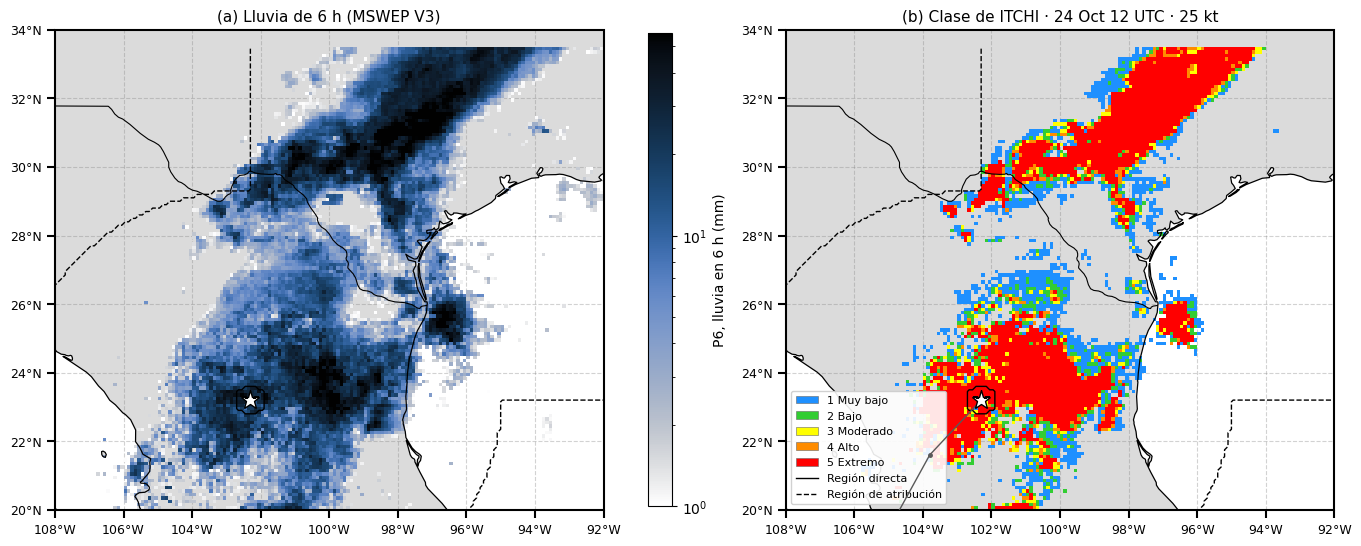

In [6]:
CASO, T = "PATRICIA2015", pd.Timestamp("2015-10-24 12:00")
LON, LAT = (-108.0, -92.0), (20.0, 34.0)
dse = xr.load_dataset(Path(cfg.cache_dir) / f"{CASO.lower()}_completa.nc")
s = dse.sel(time=T, exp=EXP)
lon, lat = dse["lon"].values, dse["lat"].values
m_dir, m_ind = s["M_direct"].values.astype(bool), s["M_indirect"].values.astype(bool)
tiene_p6 = "P6" in dse
st = estilo_zoom(LON, LAT, 2.0)
fig, axes = plt.subplots(1, 2 if tiene_p6 else 1, figsize=(13.5 if tiene_p6 else 7.5, 6),
                         subplot_kw={"projection": PC}, layout="constrained", squeeze=False)
centro = (float(s["track_lon"]), float(s["track_lat"]))

if tiene_p6:
    ax = axes[0, 0]
    configure_map_axis(ax, crs=PC, style=st)
    p6 = dse["P6"].sel(time_all=T) if "time_all" in dse["P6"].dims else dse["P6"].sel(time=T)
    p6 = p6.values
    art = ax.pcolormesh(lon, lat, np.where(p6 > 1, p6, np.nan), cmap=get_crameri_colormap("oslo", reverse=True),
                        norm=mcolors.LogNorm(1, max(10, np.nanpercentile(p6, 99.5))), transform=PC,
                        rasterized=True, zorder=2)
    regiones(ax, lon, lat, m_dir, m_ind)
    ax.plot(*centro, "*", ms=14, mfc="white", mec="k", transform=PC, zorder=8)
    fig.colorbar(art, ax=ax, shrink=0.8, label="P6, lluvia en 6 h (mm)")
    if TITULOS:
        ax.set_title("(a) Lluvia de 6 h (MSWEP V3)")

ax = axes[0, -1]
configure_map_axis(ax, crs=PC, style=st)
plot_itchi_siat_levels(np.where(s["ITCHI"].values > 0, s["ITCHI"].values, np.nan), ax, lon=lon, lat=lat, crs=PC,
                       add_colorbar=False, rasterized=True, zorder=2)
regiones(ax, lon, lat, m_dir, m_ind)
trayectoria(ax, C[CASO]["track"], color="0.35")
ax.plot(*centro, "*", ms=14, mfc="white", mec="k", transform=PC, zorder=8)
leyenda_clases(ax, extra=[Line2D([], [], color="k", lw=1.0, label="Región directa"),
                          Line2D([], [], color="k", lw=1.0, ls="--", label="Región de atribución")])
if TITULOS:
    ax.set_title(("(b) " if tiene_p6 else "") + f"Clase de ITCHI · {T:%d %b %H} UTC · {float(s['track_vmax_kt']):.0f} kt")
guardar(fig, "zoom03_patricia_texas_coahuila")

## Zoom 4 · Odile (2014), Guerrero y Oaxaca
Clase máxima del evento en la malla (solo tierra), con la trayectoria sobre Baja California para que se vea la distancia.

guardada /mnt/c/Users/adolf/Documents/ITCHI/itchi-core/outputs/figures/casos/zooms/zoom04_odile_guerrero_oaxaca


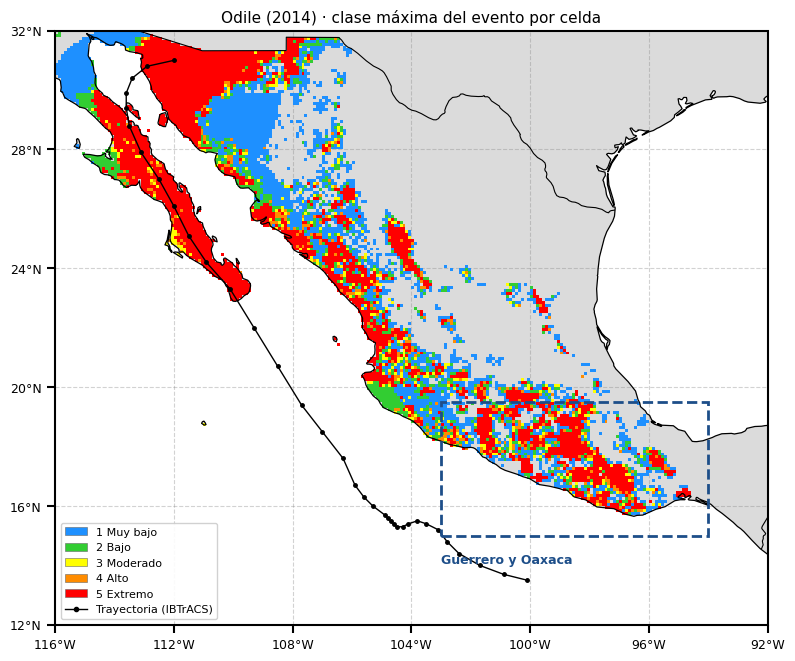

In [7]:
CASO = "ODILE2014"
LON, LAT = (-116.0, -92.0), (14.0, 32.0)
CAJA = (-103.0, -94.0, 15.0, 19.5)              # Guerrero y Oaxaca: lon0, lon1, lat0, lat1
Cc, ds = C[CASO], C[CASO]["ds"]
evmax = ds["ITCHI"].sel(exp=EXP).max("time").values
evmax = np.where((evmax > 0) & Cc["land"], evmax, np.nan)
fig, ax = plt.subplots(figsize=(8.5, 6.5), subplot_kw={"projection": PC}, layout="constrained")
configure_map_axis(ax, crs=PC, style=estilo_zoom(LON, LAT, 4.0))
plot_itchi_siat_levels(evmax, ax, lon=ds["lon"].values, lat=ds["lat"].values, crs=PC, add_colorbar=False,
                       rasterized=True, zorder=2)
trayectoria(ax, Cc["track"])
ax.add_patch(Rectangle((CAJA[0], CAJA[2]), CAJA[1] - CAJA[0], CAJA[3] - CAJA[2], fill=False, ec="#1D4E89",
                       lw=2.0, ls="--", transform=PC, zorder=7))
ax.text(CAJA[0], CAJA[2] - 0.6, "Guerrero y Oaxaca", color="#1D4E89", weight="bold", fontsize=9, transform=PC,
        va="top", zorder=7)
leyenda_clases(ax, extra=[LEY_TRAY], loc="lower left")
if TITULOS:
    ax.set_title("Odile (2014) · clase máxima del evento por celda")
guardar(fig, "zoom04_odile_guerrero_oaxaca")

## Zoom 5 (opcional) · Ubicación de los deslizamientos

/home/apereze/miniforge3/envs/itchi/lib/python3.11/site-packages/cartopy/io/img_tiles.py:113: UserWarning: Cartopy created the following directory to cache GoogleWTS tiles: /tmp/cartopy_cache_dir/GoogleTiles
  warnings.warn(


guardada /mnt/c/Users/adolf/Documents/ITCHI/itchi-core/outputs/figures/casos/zooms/zoom05_ubicacion_deslizamientos


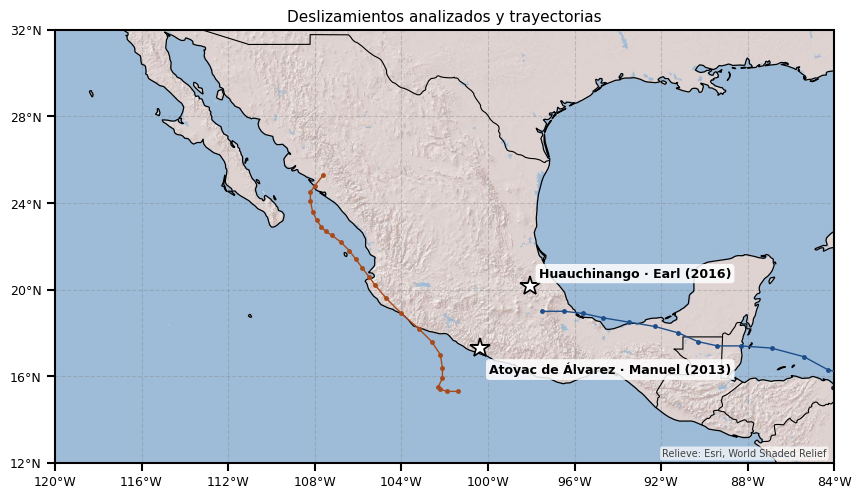

/home/apereze/miniforge3/envs/itchi/lib/python3.11/site-packages/cartopy/io/__init__.py:242: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/50m_physical/ne_50m_ocean.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


guardada /mnt/c/Users/adolf/Documents/ITCHI/itchi-core/outputs/figures/casos/zooms/zoom05_ubicacion_deslizamientos


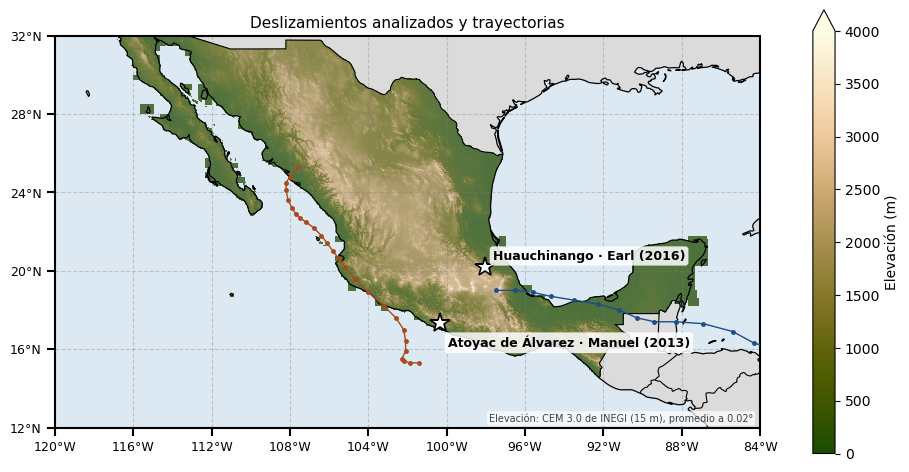

In [11]:
import cartopy.feature as cfeature
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LightSource

DEM_NC = Path("/mnt/d/DEM_mex/dem_mex_0p02.nc")
Z_MAX = 4000                                      # m; lo que pasa de aquí satura (Orizaba 5636 m)

dem = xr.open_dataset(DEM_NC)
z = dem[[v for v in dem.data_vars if dem[v].ndim == 2][0]]   # GDAL lo llama Band1
z = z.where(z > -500)                             # nodata (-9999) y mar
lon_d, lat_d = z["lon"].values, z["lat"].values
cmap_z = mcolors.ListedColormap(get_crameri_colormap("oleron")(np.linspace(0.5, 1.0, 256)))
norm_z = mcolors.Normalize(0, Z_MAX)
paso_m = 0.02 * 111e3                             # tamaño de celda en m para el sombreado
hs = LightSource(azdeg=315, altdeg=45).hillshade(np.nan_to_num(z.values, nan=0.0), vert_exag=3,
                                                 dx=paso_m, dy=paso_m)
hs = np.where(np.isfinite(z.values), hs, np.nan)

fig, ax = plt.subplots(figsize=(9, 6), subplot_kw={"projection": PC}, layout="constrained")
configure_map_axis(ax, crs=PC, style=estilo_zoom((-118.0, -86.0), (14.0, 32.0), 4.0))
ax.add_feature(cfeature.OCEAN.with_scale("50m"), facecolor="#DCE9F2", edgecolor="none", zorder=0)
ax.pcolormesh(lon_d, lat_d, z.values, cmap=cmap_z, norm=norm_z, transform=PC, rasterized=True, zorder=1)
ax.pcolormesh(lon_d, lat_d, hs, cmap="gray", vmin=0, vmax=1, alpha=0.30, transform=PC, rasterized=True, zorder=1.5)
for case, color, (dx, dy) in (("MANUEL2013", "#A84B1C", (0.4, -1.2)), ("EARL2016", "#1D4E89", (0.4, 0.4))):
    Cc, d = C[case], DESLIZAMIENTOS[case]
    g = municipios(Cc)
    trayectoria(ax, Cc["track"], color=color)
    cv = find_municipio(Cc["gdf"], d["municipio"], d["cve_ent"], d.get("cvegeo"))
    nombre = f"{CASES[case]['name'].title()} ({CASES[case]['season']})"
    punto(ax, g, cv, f"{d['municipio']} · {nombre}", dx=dx, dy=dy)
cb = fig.colorbar(ScalarMappable(norm=norm_z, cmap=cmap_z), ax=ax, shrink=0.75, extend="max")
cb.set_label("Elevación (m)")
ax.text(0.99, 0.01, "Elevación: CEM 3.0 de INEGI (15 m), promedio a 0.02°", transform=ax.transAxes,
        ha="right", va="bottom", fontsize=7, color="0.25",
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.7), zorder=9)
if TITULOS:
    ax.set_title("Deslizamientos analizados y trayectorias")
guardar(fig, "zoom05_ubicacion_deslizamientos")

In [9]:
sorted(p.name for p in FIG_DIR.glob("*.png"))

['zoom01_earl_sierra_norte.png',
 'zoom02_emily_clases_2_3.png',
 'zoom03_patricia_texas_coahuila.png',
 'zoom04_odile_guerrero_oaxaca.png',
 'zoom05_ubicacion_deslizamientos.png']

In [12]:
# 6. Video: ITCHI municipal de Patricia cada 6 h (fondo 16:9 para Canva)
import shutil, subprocess
import cartopy.feature as cfeature
from matplotlib.colors import LightSource
from itchi.municipal import municipal_values

CASO = "PATRICIA2015"
EXTENT = (-118.0, -86.0, 14.0, 32.0)              # 32° × 18° = 16:9 exacto
ANCHO, ALTO, FPS = 1920, 1080, 30
PAUSA_S, FUNDIDO_S, BUCLE = 1.0, 0.5, True        # s por tiempo, s de fundido, cerrar del último al primero
ETIQUETA = True                                   # fecha · viento · categoría en una esquina
RELIEVE = True                                    # sombreado del DEM bajo los municipios (si existe el archivo)
DEM_NC = Path("/mnt/d/DEM_mex/dem_mex_0p02.nc")
FONDO, TIERRA, LINEA = "#E7E5E1", "#F4F2EE", "#9A968F"    # mar, tierra sin peligro, contornos
MESES = {6: "jun", 7: "jul", 8: "ago", 9: "sep", 10: "oct", 11: "nov"}
OUT = FIG_DIR / "video_patricia"; OUT.mkdir(exist_ok=True)

Cc = C[CASO]
dse = xr.load_dataset(Path(cfg.cache_dir) / f"{CASO.lower()}_completa.nc")
misma = (dse.sizes["lat"] == Cc["ds"].sizes["lat"] and dse.sizes["lon"] == Cc["ds"].sizes["lon"]
         and np.allclose(dse["lat"], Cc["ds"]["lat"]) and np.allclose(dse["lon"], Cc["ds"]["lon"]))
codes = [str(c) for c in Cc["codes"]]
if misma:                                         # trayectoria completa
    it = dse["ITCHI"].sel(exp=EXP).transpose("time", "lat", "lon").values
    vals = np.asarray(municipal_values(it, Cc["pix"], Cc["codes"]), float)
    tiempos, trk = pd.DatetimeIndex(dse["time"].values), dse
else:                                             # respaldo: solo posiciones del caché
    print("mallas distintas: uso las posiciones del caché municipal")
    me = municipal_event(Cc).sel(exp=EXP)
    vals, tiempos, trk = me.transpose("mun", "time").values, pd.DatetimeIndex(me["time"].values), Cc["ds"]
if vals.shape[0] != len(codes):
    vals = vals.T
CLASES = pd.DataFrame(np.asarray(classify_itchi_to_siat_levels(vals), float), index=codes, columns=tiempos)
g = municipios(Cc)[["CVEGEO", "geometry"]]
print(len(tiempos), "tiempos:", tiempos[0], "→", tiempos[-1], "| municipios:", len(g))
print("municipios por clase en cada tiempo:\n", CLASES.apply(lambda s: s.value_counts()).fillna(0).astype(int).T.tail(8))

18 tiempos: 2015-10-20 06:00:00 → 2015-10-24 12:00:00 | municipios: 2475
municipios por clase en cada tiempo:
                       0.0  1.0  2.0  3.0  4.0  5.0
2015-10-22 18:00:00  2464    7    1    0    0    3
2015-10-23 00:00:00  2335   94   16    7    5   18
2015-10-23 06:00:00  2155  139   34   16   15  116
2015-10-23 12:00:00  2151   83   25   13   18  185
2015-10-23 18:00:00  2203   54   18   18   18  164
2015-10-24 00:00:00  2076   73   26   25   26  249
2015-10-24 06:00:00  2012   51   16    9   13  374
2015-10-24 12:00:00  2053   88   26   22   26  260


In [ ]:
def categoria(v):
    for lim, nom in ((34, "DT"), (64, "TT"), (83, "H1"), (96, "H2"), (113, "H3"), (137, "H4")):
        if v < lim:
            return nom
    return "H5"

fig = plt.figure(figsize=(ANCHO / 100, ALTO / 100), dpi=100, facecolor=FONDO)
ax = fig.add_axes([0, 0, 1, 1], projection=PC)
ax.set_extent(EXTENT, crs=PC); ax.set_facecolor(FONDO); ax.axis("off")
ax.add_feature(cfeature.LAND.with_scale("50m"), facecolor="#D9D6D0", edgecolor="none", zorder=0)
ax.add_geometries(g.geometry, crs=PC, facecolor=TIERRA, edgecolor="none", zorder=1)
if RELIEVE and DEM_NC.exists():
    z = xr.open_dataset(DEM_NC)["elevation"]
    hs = LightSource(azdeg=315, altdeg=45).hillshade(np.nan_to_num(z.values), vert_exag=3, dx=2220, dy=2220)
    ax.pcolormesh(z["lon"], z["lat"], np.where(np.isfinite(z.values), hs, np.nan), cmap="gray", vmin=0, vmax=1,
                  alpha=0.25, transform=PC, rasterized=True, zorder=1.5)
ax.add_geometries(g.geometry, crs=PC, facecolor="none", edgecolor=LINEA, linewidth=0.15, zorder=4)
ax.coastlines("50m", linewidth=0.6, color="0.35", zorder=5)
ax.add_feature(cfeature.BORDERS.with_scale("50m"), linewidth=0.6, edgecolor="0.35", zorder=5)
ax.plot(trk["track_lon"], trk["track_lat"], "-", color="0.55", lw=0.8, transform=PC, zorder=6)

def cuadro(i):
    t = tiempos[i]; vivos = []
    cls = CLASES[t]
    for k in range(1, 6):
        sub = g[g["CVEGEO"].map(cls).eq(k)]
        if len(sub):
            vivos.append(ax.add_geometries(sub.geometry, crs=PC, facecolor=SIAT_DANGER_COLORS[k],
                                           edgecolor="none", alpha=0.9, zorder=3))
    lo, la = trk["track_lon"].values[: i + 1], trk["track_lat"].values[: i + 1]
    vivos += ax.plot(lo, la, "-", color="k", lw=1.6, transform=PC, zorder=7)
    vivos += ax.plot(lo[-1], la[-1], "*", ms=16, mfc="white", mec="k", mew=1.3, transform=PC, zorder=8)
    if ETIQUETA:
        v = float(trk["track_vmax_kt"].values[i])
        vivos.append(fig.text(0.02, 0.04, f"{t.day} {MESES[t.month]} {t:%H} UTC · {v:.0f} kt ({categoria(v)})",
                              fontsize=20, color="#23272E", weight="bold"))
    fig.canvas.draw()
    rgb = np.asarray(fig.canvas.buffer_rgba())[..., :3].copy()
    fig.savefig(OUT / f"cuadro_{i:02d}.png", dpi=100, facecolor=FONDO)
    for a in vivos:
        a.remove()
    return rgb

cuadros = [cuadro(i) for i in range(len(tiempos))]
plt.close(fig)
print("cuadros listos:", len(cuadros), cuadros[0].shape)

ff = shutil.which("ffmpeg")
if ff is None:
    print("sin ffmpeg: instala con `conda install -c conda-forge ffmpeg`; los PNG ya están en", OUT)
else:
    mp4 = FIG_DIR / "patricia2015_itchi_municipal_6h.mp4"
    p = subprocess.Popen([ff, "-y", "-loglevel", "error", "-f", "rawvideo", "-pix_fmt", "rgb24",
                          "-s", f"{ANCHO}x{ALTO}", "-r", str(FPS), "-i", "-", "-c:v", "libx264",
                          "-pix_fmt", "yuv420p", "-crf", "18", str(mp4)], stdin=subprocess.PIPE)
    n_p, n_f = int(PAUSA_S * FPS), int(FUNDIDO_S * FPS)
    sec = cuadros + ([cuadros[0]] if BUCLE else [])
    for a, b in zip(sec[:-1], sec[1:]):
        for _ in range(n_p):
            p.stdin.write(a.tobytes())
        for w in np.linspace(0, 1, n_f, endpoint=False)[1:]:
            p.stdin.write(((1 - w) * a + w * b).astype(np.uint8).tobytes())
    if not BUCLE:
        for _ in range(n_p):
            p.stdin.write(sec[-1].tobytes())
    p.stdin.close(); p.wait()
    print("video:", mp4, f"| {len(cuadros) * (PAUSA_S + FUNDIDO_S):.0f} s aprox.")